In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 06 — Transformer Fine-Tuning

Fine-tune three pretrained encoders for sentence-role classification and compare them with the classical and BiLSTM models.

| Model | Hub id | Layers / hidden / params | Pretraining corpus | Casing |
|---|---|---|---|---|
| DistilBERT | `distilbert-base-uncased` (Apache-2.0) | 6 / 768 / ~67M | Wikipedia + BooksCorpus (distilled from BERT) | uncased |
| BERT-base | `bert-base-uncased` (Apache-2.0) | 12 / 768 / ~110M | Wikipedia + BooksCorpus | uncased |
| BioBERT v1.1 | `dmis-lab/biobert-base-cased-v1.1` | 12 / 768 / ~108M | BERT-cased continued on PubMed abstracts (Lee et al., 2020) | cased |

**Honest scope statement.** This machine has a CPU only (no CUDA build of PyTorch; 2 GB MX450 GPU), measured at roughly 5 s per DistilBERT step. The transformers are therefore fine-tuned on a
**small stratified subset (`config.TRAIN_SUBSET_SENTENCES` = 3,000 sentences, 1 epoch)** and evaluated on the **shared 2,000-sentence test subset**. These are real fine-tuning runs, but with
~1.7% of the training data: results measure *low-resource* behaviour and are **not** comparable to published full-data numbers. To scale up (e.g. on a Colab GPU) change only the config cell.
The classical Logistic Regression trained on the same 3,000 sentences (`tfidf_lr_8k` in notebook 04's metrics file — name kept for historical reasons, its `train_n` field states the actual size) is the fair reference.
BioBERT's hub repo ships no tokenizer files, so its tokenizer is loaded from `bert-base-cased` (same WordPiece vocabulary per the BioBERT paper).

In [2]:
import time, copy, json, psutil, torch, torch.nn as nn
import src.data as D
from transformers import AutoTokenizer, AutoModelForSequenceClassification, BertForSequenceClassification, get_linear_schedule_with_warmup
from src.evaluation import classification_metrics, measure_latency_ms, softmax
from src.utils import save_json, update_json, load_json, timer
torch.set_num_threads(4)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LAB = config.CLASS_LABELS; L2I = {l: i for i, l in enumerate(LAB)}; I2L = {i: l for l, i in L2I.items()}
# ---------------- research configuration (edit here to scale up) ----------------
CFG = dict(train_n=config.TRAIN_SUBSET_SENTENCES, epochs=config.TRAIN_EPOCHS, batch_size=config.TRAIN_BATCH_SIZE, lr=config.TRAIN_LR, max_len=config.TRAIN_MAX_SEQ_LEN,
           weight_decay=0.01, warmup_ratio=0.1, grad_clip=1.0, eval_every=40, dev_n=300)
print("device:", DEVICE, "| config:", CFG)
train, dev, test = (D.load_pubmed_rct(s) for s in ("train", "dev", "test"))
eval_sub = D.eval_subset(test); tr = D.stratified_subset(train, CFG["train_n"], config.SEED); dv = D.stratified_subset(dev, CFG["dev_n"], config.SEED)
print(len(tr), len(dv), len(eval_sub)); tr.label.value_counts().to_frame().T

device: cpu | config: {'train_n': 3000, 'epochs': 1, 'batch_size': 16, 'lr': 5e-05, 'max_len': 64, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'grad_clip': 1.0, 'eval_every': 40, 'dev_n': 300}


3001 300 2000


label,METHODS,RESULTS,CONCLUSIONS,BACKGROUND,OBJECTIVE
count,989,966,453,362,231


## 1. Tokenisation, subwords, attention masks, padding and truncation

BERT-family models use **WordPiece**: rare words are split into known sub-word units (`##` marks continuation pieces), so the vocabulary is closed (~30k) yet any word can be represented.
Batches are padded to a common length; the **attention mask** (1 = real token, 0 = padding) stops the model attending to padding. Sequences longer than `max_len` are **truncated**.

In [3]:
tok_d = AutoTokenizer.from_pretrained(config.HF_DISTILBERT); tok_b = AutoTokenizer.from_pretrained(config.HF_BIOBERT_TOKENIZER)
s = ["Patients received 5 mg/kg of metformin versus placebo.", "Hypoglycemia and nephrotoxicity were not observed."]
for name, tk in [("uncased (DistilBERT/BERT)", tok_d), ("cased (BioBERT)", tok_b)]:
    enc = tk(s, padding=True, truncation=True, max_length=16, return_tensors="pt")
    print(name); [print("  ", tk.convert_ids_to_tokens(ids)) for ids in enc["input_ids"]]; print("   attention_mask:", enc["attention_mask"].tolist())
lens = [len(x) for x in tok_d(tr.text.tolist()[:2000])["input_ids"]]
print(f"\nword-piece length: median {np.median(lens):.0f}, 95th pct {np.percentile(lens, 95):.0f}, max {max(lens)}; truncation at 64 affects {np.mean(np.array(lens) > 64):.1%}, at 32 affects {np.mean(np.array(lens) > 32):.1%} of sentences")

uncased (DistilBERT/BERT)
   ['[CLS]', 'patients', 'received', '5', 'mg', '/', 'kg', 'of', 'met', '##form', '##in', 'versus', 'place', '##bo', '.', '[SEP]']
   ['[CLS]', 'h', '##yp', '##og', '##ly', '##ce', '##mia', 'and', 'ne', '##ph', '##rot', '##ox', '##ici', '##ty', 'were', '[SEP]']
   attention_mask: [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]
cased (BioBERT)
   ['[CLS]', 'Pat', '##ients', 'received', '5', 'mg', '/', 'kg', 'of', 'met', '##form', '##in', 'versus', 'place', '##bo', '[SEP]']
   ['[CLS]', 'H', '##y', '##po', '##gly', '##ce', '##mia', 'and', 'ne', '##ph', '##rot', '##ox', '##icit', '##y', 'were', '[SEP]']
   attention_mask: [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]



word-piece length: median 33, 95th pct 79, max 250; truncation at 64 affects 9.6%, at 32 affects 50.1% of sentences


## 2. The attention mechanism (illustration)

Self-attention computes, for every token, a weighted average of all tokens' value vectors, with weights `softmax(QKᵀ/√d)`. Below: the **head-averaged last-layer attention** of the *pretrained, not yet fine-tuned* DistilBERT for one sentence.

> **Caveat (important for explainability):** attention weights show *where information flowed*, not *why a prediction was made*. Attention is not a faithful explanation of model behaviour (Jain & Wallace, 2019); MediScope's UI therefore explains predictions with **occlusion-based attribution**, not attention.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


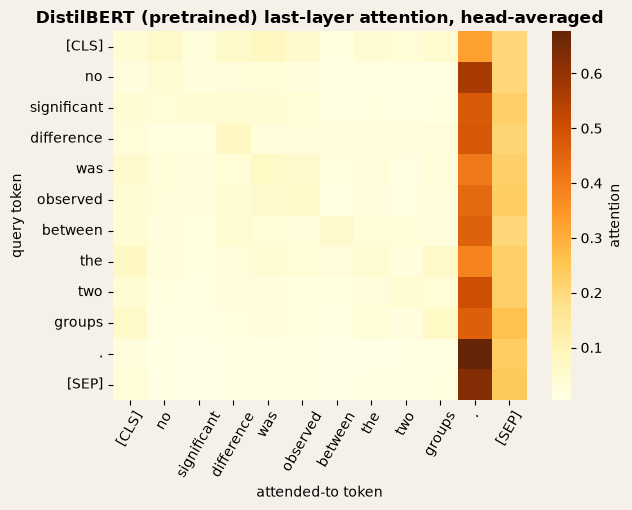

> **Observation.** Row sums are 1 (each token distributes one unit of attention). On average 27% of every token's attention goes to the two special tokens `[CLS]`/`[SEP]` in this example, i.e. a large share of attention mass lands on non-content tokens — one reason raw attention is a poor explanation.

In [4]:
m_att = AutoModelForSequenceClassification.from_pretrained(config.HF_DISTILBERT, num_labels=5, attn_implementation="eager").eval()
sent = "No significant difference was observed between the two groups."
enc = tok_d(sent, return_tensors="pt")
with torch.no_grad(): att = m_att(**enc, output_attentions=True).attentions[-1][0].mean(0).numpy()
toks = tok_d.convert_ids_to_tokens(enc["input_ids"][0])
fig, ax = plt.subplots(figsize=(6.5, 5.2)); sns.heatmap(att, xticklabels=toks, yticklabels=toks, cmap="YlOrBr", ax=ax, cbar_kws={"label": "attention"}); ax.set_title("DistilBERT (pretrained) last-layer attention, head-averaged"); ax.set_xlabel("attended-to token"); ax.set_ylabel("query token")
plt.xticks(rotation=60); plt.tight_layout(); plt.show(); del m_att
sp_share = float(att[:, [0, -1]].sum(1).mean())
note(f"Row sums are 1 (each token distributes one unit of attention). On average {sp_share:.0%} of every token's attention goes to the two special tokens `[CLS]`/`[SEP]` in this example, "
     f"i.e. a large share of attention mass lands on non-content tokens — one reason raw attention is a poor explanation.")

## 3. Fine-tuning procedure

* **Model head:** pretrained encoder + dropout + linear(5) on the `[CLS]` representation.
* **Optimiser:** AdamW with **decoupled weight decay 0.01**, applied to weights but *not* to biases/LayerNorm parameters (standard practice).
* **Schedule:** linear warm-up (10% of steps) then linear decay to 0 — avoids destabilising pretrained weights with a large early learning rate.
* **Regularisation / stability:** gradient clipping at 1.0; fixed seed.
* **Batching:** dynamic padding per batch (shorter sequences are cheaper on CPU).
* **Validation:** every 40 steps on a fixed 300-sentence dev sample (validation loss + macro-F1), **best checkpoint kept** (weights restored at the end) and written to disk (`artifacts/classification/checkpoints/`, git-ignored) — a crashed run can be resumed by loading the checkpoint.
* **GPU/CPU:** device is selected automatically; mixed precision (`torch.autocast`) is switched on only when CUDA is available.

In [5]:
def make_model(model_id, tok_id):
    kw = dict(num_labels=5, id2label=I2L, label2id=L2I)
    m = BertForSequenceClassification.from_pretrained(model_id, **kw) if "biobert" in model_id else AutoModelForSequenceClassification.from_pretrained(model_id, **kw)
    return AutoTokenizer.from_pretrained(tok_id), m.to(DEVICE)

def predict_logits(model, tok, texts, max_len, bs=32):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            enc = tok(texts[i:i + bs], truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(DEVICE); out.append(model(**enc).logits.float().cpu().numpy())
    return np.vstack(out)

def finetune(name, model_id, tok_id, data, cfg, ckpt=True, verbose=True):
    set_seed(config.SEED); tok, model = make_model(model_id, tok_id)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in model.named_parameters() if not any(x in n for x in nd)], "weight_decay": cfg["weight_decay"]},
              {"params": [p for n, p in model.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=cfg["lr"]); steps = cfg["epochs"] * int(np.ceil(len(data) / cfg["batch_size"]))
    sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup_ratio"] * steps), steps)
    texts, y = data.text.tolist(), data.label.map(L2I).values; log, best, best_state, step = [], -1, None, 0; t0 = time.time(); tl, nb = 0, 0
    scaler_ctx = (lambda: torch.autocast("cuda", dtype=torch.float16)) if DEVICE == "cuda" else (lambda: torch.autocast("cpu", enabled=False))
    for ep in range(cfg["epochs"]):
        perm = np.random.permutation(len(texts))
        for i in range(0, len(texts), cfg["batch_size"]):
            model.train(); j = perm[i:i + cfg["batch_size"]]
            enc = tok([texts[k] for k in j], truncation=True, max_length=cfg["max_len"], padding=True, return_tensors="pt").to(DEVICE)
            with scaler_ctx(): loss = nn.functional.cross_entropy(model(**enc).logits, torch.as_tensor(y[j]).to(DEVICE))
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"]); opt.step(); sched.step(); opt.zero_grad()
            step += 1; tl += loss.item(); nb += 1
            if step % cfg["eval_every"] == 0 or step == steps:
                lg = predict_logits(model, tok, dv.text.tolist(), cfg["max_len"]); yd = dv.label.map(L2I).values
                vl = float(nn.functional.cross_entropy(torch.as_tensor(lg), torch.as_tensor(yd)).item()); f1 = classification_metrics([I2L[i] for i in yd], [I2L[i] for i in lg.argmax(1)], LAB)["f1_macro"]
                log.append({"step": step, "epoch": ep + step / steps * cfg["epochs"], "train_loss": tl / nb, "val_loss": vl, "val_macro_f1": f1, "elapsed_s": time.time() - t0}); tl, nb = 0, 0
                if verbose: print(f"[{name}] step {step}/{steps} train_loss {log[-1]['train_loss']:.4f} val_loss {vl:.4f} val_macro_F1 {f1:.4f} ({time.time()-t0:.0f}s)")
                if f1 > best:
                    best = f1; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                    if ckpt: d = config.ART_CLS / "checkpoints" / name; d.mkdir(parents=True, exist_ok=True); torch.save(best_state, d / "best.pt")
    model.load_state_dict(best_state)
    return tok, model, pd.DataFrame(log), time.time() - t0

## 4. Experiments on hyper-parameters (DistilBERT, 600-sentence budget)

Because every run costs minutes on CPU, the hyper-parameter study is deliberately small: **one factor at a time** around a base configuration (lr 5e-5, batch 16, max_len 64), on 600 training sentences, scored by dev macro-F1 on the fixed 300-sentence dev sample.
Treat these as directional; differences smaller than a few points are within noise at this scale (a single seed).

In [6]:
small = D.stratified_subset(train, 600, config.SEED); EXP = {}
variants = {"base (lr 5e-5, bs 16, len 64)": {}, "lr 2e-5": {"lr": 2e-5}, "batch 32": {"batch_size": 32}, "max_len 32": {"max_len": 32}}
for k, ov in variants.items():
    cfg = {**CFG, **ov, "eval_every": 10_000}; _, m, lg, secs = finetune("exp", config.HF_DISTILBERT, config.HF_DISTILBERT, small, cfg, ckpt=False, verbose=False)
    EXP[k] = {"val_macro_f1": float(lg.val_macro_f1.max()), "val_loss": float(lg.val_loss.iloc[-1]), "seconds": secs}; del m
exp = pd.DataFrame(EXP).T; display(exp.round(4)); update_json(config.ART_CLS / "ablations.json", "transformer_hparams_distilbert_600", exp.round(4).to_dict("index"))
b0 = exp.iloc[0].val_macro_f1
note("Relative to the base configuration (dev macro-F1 %.4f): " % b0 + "; ".join(f"**{k}** {v - b0:+.4f}" for k, v in exp.val_macro_f1.iloc[1:].items()) +
     f". Wall-clock: max_len 32 took {exp.loc['max_len 32','seconds']:.0f}s vs {exp.iloc[0].seconds:.0f}s for 64 — the speed/accuracy trade-off asked about in the brief. Epoch-count and larger-batch sweeps were not run (compute budget).")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,val_macro_f1,val_loss,seconds
"base (lr 5e-5, bs 16, len 64)",0.3118,1.0215,217.6279
lr 2e-5,0.2769,1.3533,255.0999
batch 32,0.2917,1.2611,210.2028
max_len 32,0.3017,1.0679,94.0000


> **Observation.** Relative to the base configuration (dev macro-F1 0.3118): **lr 2e-5** -0.0349; **batch 32** -0.0201; **max_len 32** -0.0102. Wall-clock: max_len 32 took 94s vs 218s for 64 — the speed/accuracy trade-off asked about in the brief. Epoch-count and larger-batch sweeps were not run (compute budget).

## 5. Fine-tune the three models

In [7]:
MODELS = {"distilbert": (config.HF_DISTILBERT, config.HF_DISTILBERT, "DistilBERT"), "bert": (config.HF_BERT, config.HF_BERT, "BERT-base"), "biobert": (config.HF_BIOBERT, config.HF_BIOBERT_TOKENIZER, "BioBERT v1.1")}
HIST, RES = {}, {}
for key, (mid, tid, label) in MODELS.items():
    tok, model, lg, secs = finetune(key, mid, tid, tr, CFG)
    HIST[key] = lg
    texts = eval_sub.text.tolist(); t0 = time.time(); L = predict_logits(model, tok, texts, config.INFER_MAX_SEQ_LEN); inf_s = time.time() - t0
    P = softmax(L); pred = [I2L[i] for i in P.argmax(1)]; m = classification_metrics(eval_sub.label, pred, LAB)
    dd = config.ART_CLS / "transformers" / key; dd.mkdir(parents=True, exist_ok=True); model.save_pretrained(dd); tok.save_pretrained(dd)
    size_mb = sum(f.stat().st_size for f in dd.glob("*.safetensors")) / 1e6
    lat = measure_latency_ms(lambda b: predict_logits(model, tok, b, config.INFER_MAX_SEQ_LEN), texts[:64], repeats=2)
    res = {"kind": "transformer", "label": label, "train_n": len(tr), "epochs": CFG["epochs"], "train_seconds": secs, "params": sum(p.numel() for p in model.parameters()), "model_mb": size_mb,
           "latency_ms": lat, "peak_rss_mb": psutil.Process().memory_info().rss / 1e6, "eval_seconds": inf_s, "cfg": CFG, "test_full": None, "best_val_macro_f1": float(lg.val_macro_f1.max())}
    res.update(m); RES[key] = res
    np.savez_compressed(config.ART_EVAL / f"preds_{key}.npz", probs=P.astype("float32"), y=eval_sub.label.map(L2I).values)
    update_json(config.ART_CLS / "metrics.json", key, res); save_json(lg.to_dict("records"), config.ART_EVAL / f"{key}_history.json")
    print(f"==> {label}: subset macro-F1 {m['f1_macro']:.4f} acc {m['accuracy']:.4f} | train {secs:.0f}s | {lat:.1f} ms/sent | {size_mb:.0f} MB\n")
    del model, tok

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[distilbert] step 40/188 train_loss 1.3527 val_loss 0.9002 val_macro_F1 0.4821 (174s)


[distilbert] step 80/188 train_loss 0.7971 val_loss 0.6370 val_macro_F1 0.5565 (419s)


[distilbert] step 120/188 train_loss 0.6469 val_loss 0.5464 val_macro_F1 0.7212 (547s)


[distilbert] step 160/188 train_loss 0.5898 val_loss 0.5336 val_macro_F1 0.7481 (669s)


... (19 outputs left out)

[biobert] step 160/188 train_loss 0.4943 val_loss 0.4167 val_macro_F1 0.7900 (976s)


[biobert] step 188/188 train_loss 0.4937 val_loss 0.3974 val_macro_F1 0.7869 (1129s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

==> BioBERT v1.1: subset macro-F1 0.7986 acc 0.8575 | train 1129s | 60.0 ms/sent | 433 MB



## 6. Training curves

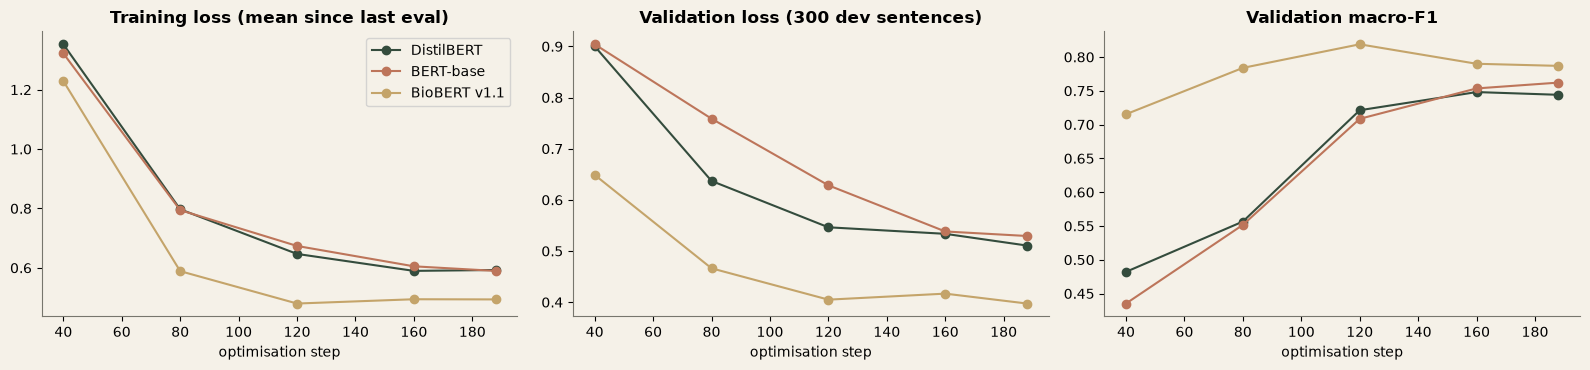

> **Observation.** Final (train loss, validation loss): **DistilBERT** (0.593, 0.511); **BERT-base** (0.590, 0.529); **BioBERT v1.1** (0.494, 0.397). With one epoch over a small subset, training and validation loss are expected to stay close — this is an *under-trained* regime, not an overfitting one.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for (k, h), c in zip(HIST.items(), PALETTE):
    axes[0].plot(h.step, h.train_loss, "o-", label=MODELS[k][2], color=c); axes[1].plot(h.step, h.val_loss, "o-", color=c); axes[2].plot(h.step, h.val_macro_f1, "o-", color=c)
axes[0].set_title("Training loss (mean since last eval)"); axes[1].set_title("Validation loss (300 dev sentences)"); axes[2].set_title("Validation macro-F1")
[a.set_xlabel("optimisation step") for a in axes]; axes[0].legend(); plt.tight_layout(); plt.show()
fin = {k: (h.train_loss.iloc[-1], h.val_loss.iloc[-1]) for k, h in HIST.items()}
note("Final (train loss, validation loss): " + "; ".join(f"**{MODELS[k][2]}** ({a:.3f}, {b:.3f})" for k, (a, b) in fin.items()) +
     ". With one epoch over a small subset, training and validation loss are expected to stay close — this is an *under-trained* regime, not an overfitting one.")

## 7. Results and comparison with non-transformer models

In [9]:
M = load_json(config.ART_CLS / "metrics.json")
keys = ["tfidf_lr_8k", "tfidf_lr", "bilstm", "distilbert", "bert", "biobert"]
rows = {}
for k in keys:
    if k not in M: continue
    v = M[k]; rows[k] = {"model": v["label"], "train n": v["train_n"], "accuracy": v["accuracy"], "macro-F1": v["f1_macro"], "weighted-F1": v["f1_weighted"], "macro-P": v["precision_macro"], "macro-R": v["recall_macro"],
                         "train s": v["train_seconds"], "ms/sent": v["latency_ms"], "MB": v["model_mb"]}
cmp_ = pd.DataFrame(rows).T.set_index("model"); display(cmp_.style.format({c: "{:.4f}" for c in ["accuracy", "macro-F1", "weighted-F1", "macro-P", "macro-R"]} | {"train s": "{:.0f}", "ms/sent": "{:.2f}", "MB": "{:.0f}"}).background_gradient(subset=["macro-F1"], cmap="YlGn"))
tm = {k: RES[k]["f1_macro"] for k in RES}; best_t = max(tm, key=tm.get)
note(f"All numbers above are on the same {len(eval_sub):,}-sentence test subset. Best transformer: **{MODELS[best_t][2]}** (macro-F1 {tm[best_t]:.4f}). "
     f"Biomedical vs general-purpose BERT-base (same architecture, same budget): BioBERT − BERT = {tm['biobert'] - tm['bert']:+.4f} macro-F1 (cased vs uncased is a confound, and with n={len(eval_sub):,} the 95% interval is roughly ±{1.96*np.sqrt(.8*.2/len(eval_sub))*100:.1f} accuracy points). "
     f"DistilBERT is {RES['distilbert']['train_seconds'] / RES['bert']['train_seconds']:.2f}× the training time and {RES['distilbert']['latency_ms'] / RES['bert']['latency_ms']:.2f}× the latency of BERT-base. "
     f"Reference: Logistic Regression trained on the same {len(tr):,} sentences reaches {M.get('tfidf_lr_8k', {}).get('f1_macro', float('nan')):.4f}.")

,train n,accuracy,macro-F1,weighted-F1,macro-P,macro-R,train s,ms/sent,MB
model,,,,,,,,,
"Logistic Regression (3k, transformer-matched)",3001,0.7570,0.6927,0.7572,0.6922,0.6944,3,0.11,0
Logistic Regression,180040,0.8245,0.7706,0.8258,0.7670,0.7751,143,0.10,6
BiLSTM,30000,0.8200,0.7617,0.8196,0.7686,0.7575,439,0.58,13
DistilBERT,3001,0.8060,0.7428,0.8041,0.7535,0.7349,762,38.37,268
BERT-base,3001,0.8090,0.7482,0.8078,0.7619,0.7408,1157,84.41,438
BioBERT v1.1,3001,0.8575,0.7986,0.8566,0.8024,0.7985,1129,60.05,433


> **Observation.** All numbers above are on the same 2,000-sentence test subset. Best transformer: **BioBERT v1.1** (macro-F1 0.7986). Biomedical vs general-purpose BERT-base (same architecture, same budget): BioBERT − BERT = +0.0504 macro-F1 (cased vs uncased is a confound, and with n=2,000 the 95% interval is roughly ±1.8 accuracy points). DistilBERT is 0.66× the training time and 0.45× the latency of BERT-base. Reference: Logistic Regression trained on the same 3,001 sentences reaches 0.6927.

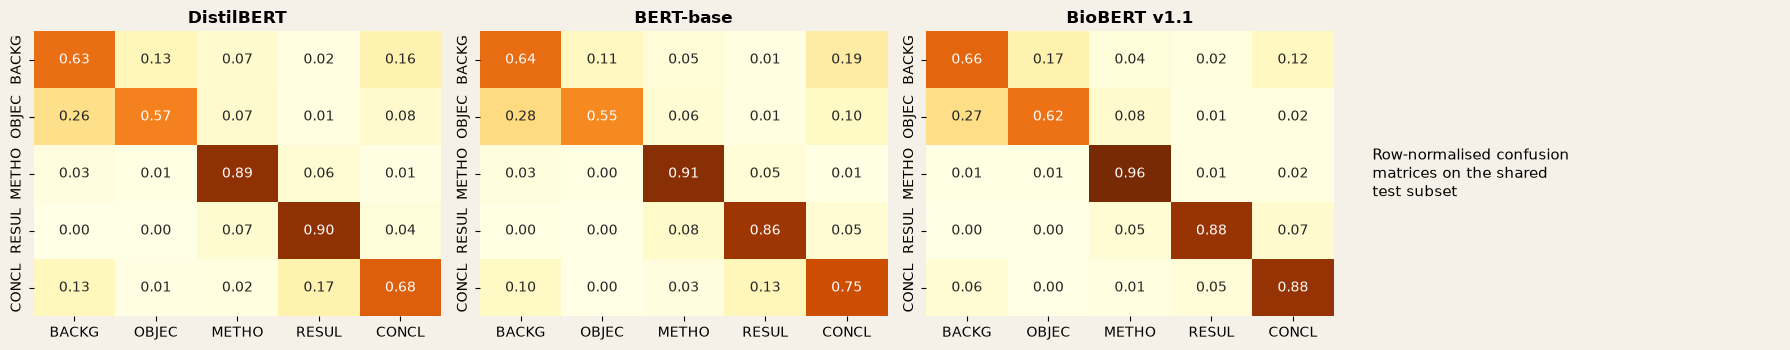

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, k in zip(axes, RES):
    cmx = np.array(RES[k]["confusion_matrix"]); sns.heatmap(cmx / cmx.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="YlOrBr", xticklabels=[l[:5] for l in LAB], yticklabels=[l[:5] for l in LAB], cbar=False, ax=ax, vmin=0, vmax=1); ax.set_title(MODELS[k][2])
axes[3].axis("off"); axes[3].text(0, .5, "Row-normalised confusion\nmatrices on the shared\ntest subset", fontsize=11, va="center"); plt.tight_layout(); plt.show()

## 8. Computational considerations

* **Memory:** peak resident memory is recorded per run (`peak_rss_mb`, cumulative within the notebook process, so read it as an upper bound that grows as models are loaded). A BERT-base AdamW fine-tune needs ≈ 4× the parameter size for weights + gradients + optimiser moments (~1.7 GB fp32), which already exceeds the 2 GB MX450 once activations are added — the reason training ran on CPU.
* **GPU path:** on a CUDA machine the same code uses `torch.autocast(float16)` automatically; raise `train_n`, `epochs` and `batch_size` in the config cell.
* **Checkpointing / resumption:** the best checkpoint is saved to `artifacts/classification/checkpoints/<model>/best.pt`; final models in Hugging Face format to `artifacts/classification/transformers/<model>/` (both git-ignored because of size).

## Conclusions

* Three transformers were genuinely fine-tuned (small budget), evaluated on a shared test subset and compared against matched-budget classical models; weights were saved for the Flask app.
* Because of the tiny training budget, *conclusions about architecture quality are limited*; the comparison is best read as **low-resource sample efficiency** plus **cost** (time, latency, size).